In [1]:
ROLL_NO = 1024170210        # <-- your full roll number
NAME = "Maansi"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

In [8]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

In [9]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [10]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170210   Name: Maansi   Fingerprint: E22D1106   Tickets: 12

Ticket_ID                                                                                 Ticket_Text
      T01            Matlab stopped responding when I use mobile hotspot. I have tried several times!
      T02                        E-mail is running slowly since yesterday. Is there another solution?
      T03                                The MATLAB was working yesterday. Is there another solution?
      T04    I couldn't connect to the VPN after resetting my password. It works on another computer.
      T05                                         The email crashes while opening. Please resolve it.
      T06 I am unable to use the student portal when I use mobile hotspot. Is there another solution?
      T07                               Wifi was working yesterday during the lab. Please resolve it.
      T08     Python was working yesterday when connected to campus Wi-Fi. Is there another solution?
    

In [12]:
print(df.columns.tolist())

['Ticket_ID', 'Ticket_Text']


## Q1- Preprocessing pipeline


In [13]:

import pandas as pd

rows = []
processed_tickets = {}

for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    result = process_ticket(text)
    processed_tickets[ticket_id] = result

    rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

table = pd.DataFrame(rows)

# Add TOTAL row
total = {"Ticket_ID": "TOTAL"}

for col in table.columns[1:]:
    total[col] = table[col].sum()

table = pd.concat(
    [table, pd.DataFrame([total])],
    ignore_index=True
)

display(table)

# Display actual tokens for one selected ticket
selected_id = df["Ticket_ID"].iloc[0]
selected = processed_tickets[selected_id]

print("\nSelected Ticket ID:", selected_id)
print("Actual tokens:", selected["tokens"])
print("Punctuation tokens:", selected["punct"])
print("Stopwords:", selected["stops"])
print("Final tokens:", selected["final"])


,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,15,2,4,14,9
1,T02,2,12,2,3,11,7
2,T03,2,11,2,4,11,5
3,T04,2,18,2,7,17,9
4,T05,2,10,2,3,9,5
5,T06,2,19,2,8,17,9
6,T07,2,12,2,4,11,6
7,T08,2,15,2,5,15,8
8,T09,1,7,1,3,7,3
9,T10,2,7,2,3,6,2



Selected Ticket ID: T01
Actual tokens: ['matlab', 'stopped', 'responding', 'when', 'i', 'use', 'mobile', 'hotspot', '.', 'i', 'have', 'tried', 'several', 'times', '!']
Punctuation tokens: ['.', '!']
Stopwords: ['when', 'i', 'i', 'have']
Final tokens: ['matlab', 'stopped', 'responding', 'use', 'mobile', 'hotspot', 'tried', 'several', 'times']


## Regular Expressions

In [15]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]


In [16]:

import re

# Use the raw ticket texts
raw_tickets = df["Ticket_Text"].tolist()

# Regex patterns
long_words_pattern = r"\b[A-Za-z]{6,}\b"
numbers_pattern = r"\b\d+(?:\.\d+)*\b"
capitalized_pattern = r"\b[A-Z][a-zA-Z]*\b"
vowel_words_pattern = r"\b[aeiouAEIOU][a-zA-Z]*\b"

# Extract from each raw ticket
for i, ticket in enumerate(raw_tickets, start=1):
    print(f"\nTicket {i}: {ticket}")
    print("Words longer than 5 letters:",
          re.findall(long_words_pattern, ticket))
    print("Numbers:",
          re.findall(numbers_pattern, ticket))
    print("Capitalized words:",
          re.findall(capitalized_pattern, ticket))
    print("Words beginning with a vowel:",
          re.findall(vowel_words_pattern, ticket))

# Replacement patterns
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"\b(?:https?://|www\.)[^\s,;]+\b"
phone_pattern = r"(?<!\w)(?:\+91[\s-]?)?(?:\d{3}[\s-]?\d{3}[\s-]?\d{4}|\d{10})(?!\w)"

def anonymize(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("\n--- Replacement on raw tickets ---")
for ticket in raw_tickets:
    print(anonymize(ticket))

# Test the required TEST_LINES
print("\n--- TEST_LINES results ---")
for line in TEST_LINES:
    print("\nOriginal:", line)
    print("Long words:", re.findall(long_words_pattern, line))
    print("Numbers:", re.findall(numbers_pattern, line))
    print("Capitalized words:", re.findall(capitalized_pattern, line))
    print("Vowel-starting words:", re.findall(vowel_words_pattern, line))
    print("Replaced:", anonymize(line))



Ticket 1: Matlab stopped responding when I use mobile hotspot. I have tried several times!
Words longer than 5 letters: ['Matlab', 'stopped', 'responding', 'mobile', 'hotspot', 'several']
Numbers: []
Capitalized words: ['Matlab', 'I', 'I']
Words beginning with a vowel: ['I', 'use', 'I']

Ticket 2: E-mail is running slowly since yesterday. Is there another solution?
Words longer than 5 letters: ['running', 'slowly', 'yesterday', 'another', 'solution']
Numbers: []
Capitalized words: ['E', 'Is']
Words beginning with a vowel: ['E', 'is', 'Is', 'another']

Ticket 3: The MATLAB was working yesterday. Is there another solution?
Words longer than 5 letters: ['MATLAB', 'working', 'yesterday', 'another', 'solution']
Numbers: []
Capitalized words: ['The', 'MATLAB', 'Is']
Words beginning with a vowel: ['Is', 'another']

Ticket 4: I couldn't connect to the VPN after resetting my password. It works on another computer.
Words longer than 5 letters: ['couldn', 'connect', 'resetting', 'password', 'ano

In [19]:

import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

# One regex pattern covering all required token types
pattern = (
    r"https?://[^\s,;]+|www\.[^\s,;]+|"  # URLs
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"  # Emails
    r"\+?\d+(?:[\s-]\d+){2,}|"  # Phone numbers
    r"\d+(?:\.\d+)+|"  # Decimals and versions
    r"[A-Za-z]+(?:-[A-Za-z]+)*|"  # Hyphenated words
    r"[A-Za-z]+(?:'[A-Za-z]+)*|"  # Words and contractions
    r"\d+|"  # Integers
    r"[^\w\s]"  # Remaining punctuation
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

# Run on TEST_LINES
print("========== TEST_LINES ==========")
for line in TEST_LINES:
    print("\nText:", line)
    print("Custom tokens:", my_tokenize(line))
    print("NLTK tokens:", word_tokenize(line))

# Run on raw tickets
print("\n========== RAW TICKETS ==========")
for _, row in df.iterrows():
    text = row["Ticket_Text"]
    print(f"\n{row['Ticket_ID']}: {text}")
    print("Custom tokens:", my_tokenize(text))
    print("NLTK tokens:", word_tokenize(text))

# Identify differences
print("\n========== TOKENIZATION DIFFERENCES ==========")
for line in TEST_LINES:
    custom = my_tokenize(line)
    nltk_tokens = word_tokenize(line)

    if custom != nltk_tokens:
        print("\nText:", line)
        print("Custom:", custom)
        print("NLTK:", nltk_tokens)


========== TEST_LINES ==========

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom tokens: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
NLTK tokens: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom tokens: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
NLTK tokens: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in

## Q4- stemming and Lemmatization

In [21]:

import pandas as pd
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

# Download required resources
for resource in [
    "wordnet",
    "omw-1.4",
    "averaged_perceptron_tagger_eng"
]:
    nltk.download(resource, quiet=True)

# Collect unique final tokens from Q1
unique_tokens = sorted({
    token.lower()
    for result in processed_tickets.values()
    for token in result["final"]
    if token.isalpha()
})

# Initialize stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()

# Choose a suffix based on words in the dataset:
# "responding" -> "respond", "working" -> "work"
# Justification: -ing is a common inflectional suffix in the tickets.
regex_stemmer = RegexpStemmer(r"ing$", min=4)

lemmatizer = WordNetLemmatizer()

# Convert Penn Treebank POS tags to WordNet POS
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    return "n"

# POS-tag all unique tokens
tagged_tokens = pos_tag(unique_tokens)

rows = []

for word, tag in tagged_tokens:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regex_stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, get_wordnet_pos(tag))

    # Keep only words with differing outputs
    if len({p, l, r, lemma}) > 1:
        rows.append({
            "Word": word,
            "Porter Stem": p,
            "Lancaster Stem": l,
            "Regexp Stem": r,
            "WordNet Lemma": lemma
        })

comparison = pd.DataFrame(
    rows,
    columns=[
        "Word",
        "Porter Stem",
        "Lancaster Stem",
        "Regexp Stem",
        "WordNet Lemma"
    ]
)

display(comparison)
print("Number of words with differing outputs:", len(comparison))



,Word,Porter Stem,Lancaster Stem,Regexp Stem,WordNet Lemma
0,another,anoth,anoth,another,another
1,campus,campu,camp,campus,campus
2,computer,comput,comput,computer,computer
3,connected,connect,connect,connected,connect
4,crashes,crash,crash,crashes,crash
5,file,file,fil,file,file
6,fixed,fix,fix,fixed,fix
7,mobile,mobil,mobl,mobile,mobile
8,opening,open,op,open,open
9,please,pleas,pleas,please,please


Number of words with differing outputs: 30


## Q-5 Corpus Statistics

CORPUS STATISTICS


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1,143,71,0.4965
1,S2,118,65,0.5508
2,S3,70,48,0.6857
3,S4,70,46,0.6571



Top 10 words in S1:
[('.', 14), ('is', 9), ('?', 7), ('the', 7), ('i', 5), ('another', 5), ('yesterday', 4), ('there', 4), ('solution', 4), ('it', 4)]

Top 10 words in S3:
[('another', 5), ('yesterday', 4), ('solution', 4), ('use', 3), ('working', 3), ('matlab', 2), ('mobile', 2), ('hotspot', 2), ("n't", 2), ('opening', 2)]


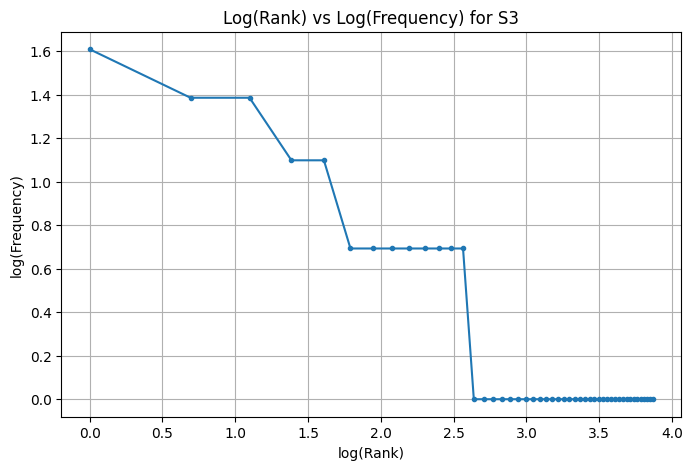


Top 5 bigrams in S1:
[(('.', 'is'), 6), (('is', 'there'), 4), (('there', 'another'), 4), (('another', 'solution'), 4), (('solution', '?'), 4)]

Top 5 bigrams in S3:
[(('another', 'solution'), 4), (('working', 'yesterday'), 3), (('use', 'mobile'), 2), (('mobile', 'hotspot'), 2), (('yesterday', 'another'), 2)]


In [23]:

import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import bigrams

# Build the four corpora from all raw tickets
S1 = []
S2 = []
S3 = []

for text in df["Ticket_Text"]:
    result = process_ticket(text)

    S1.extend(result["tokens"])   # All tokens, including punctuation
    S2.extend(result["stops"] + result["final"] + result["punct"])
    S3.extend(result["final"])    # Final tokens after preprocessing

# S2: all tokens without punctuation
# Use the official token list to preserve the original token order
S2 = []
for text in df["Ticket_Text"]:
    result = process_ticket(text)
    S2.extend([t for t in result["tokens"] if not is_punct(t)])

# S4: S3 after Porter stemming
porter = PorterStemmer()
S4 = [porter.stem(token) for token in S3]

corpora = {
    "S1": S1,
    "S2": S2,
    "S3": S3,
    "S4": S4
}

# Calculate corpus statistics
stats = []

for name, corpus in corpora.items():
    total = len(corpus)
    unique = len(set(corpus))
    ttr = unique / total if total else 0

    stats.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

print("CORPUS STATISTICS")
display(pd.DataFrame(stats))

# Top 10 words in S1 and S3
for name in ["S1", "S3"]:
    print(f"\nTop 10 words in {name}:")
    print(Counter(corpora[name]).most_common(10))

# Log(rank) vs log(frequency) for S3
freq = Counter(S3)
ranked_freq = sorted(freq.values(), reverse=True)

ranks = list(range(1, len(ranked_freq) + 1))
log_ranks = [math.log(r) for r in ranks]
log_freqs = [math.log(f) for f in ranked_freq]

plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_freqs, marker=".")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()

# Top 5 bigrams in S1 and S3
for name in ["S1", "S3"]:
    bigram_counts = Counter(bigrams(corpora[name]))
    print(f"\nTop 5 bigrams in {name}:")
    print(bigram_counts.most_common(5))
